# PhishGuard: project walkthrough

**CSL236 Introduction to AI and Machine Learning, end-term project**
Shivansh Saroha (24CSU192), The NorthCap University

This notebook explains the whole machine-learning side of PhishGuard, from the raw dataset to the model running behind
the live app (https://ai-phising-detector-kgt4.onrender.com). Read it top to bottom: every code cell has a short note
above it saying **what** it does and **why**, and a note below the important outputs saying **what to take away**.

| Section | Question it answers |
|---|---|
| 1. Setup | What do we need to run this? |
| 2. The dataset | Where does the data come from and what does it look like? |
| 3. EDA: the shortcut | Why does the model look only at the hostname? |
| 4. Cleaning | How do we turn 235,795 URLs into a fair training set? |
| 5. Feature engineering | How does a domain name become numbers a model can learn from? |
| 6. Training | Which algorithm works best, and how do we compare them fairly? |
| 7. Evaluation | How good is the best model, really? |
| 8. Explainability | Which features does the model rely on? |
| 9. Threshold | What happens if we flag more (or fewer) links? |
| 10. Error analysis | What does the model get wrong, and why? |
| 11. The saved model and the API | How does the deployed app use all this? |
| 12. Conclusions | What did we learn, and what are the limits? |

> **How to run:** from the repo root, `pip install -r requirements.txt matplotlib notebook`, then
> `jupyter notebook notebooks/PhishGuard_Walkthrough.ipynb` and *Run All*. Training cells take about a minute.
> The notebook trains its own copies of the models and **never overwrites** `model/model.joblib`.

## 1. Setup

We import the usual data-science libraries, plus `features.py` from the project root. That file is the **same feature
code the live API uses**, so everything we show here is exactly what happens in production.

`ROOT` finds the project folder whether you start Jupyter from the repo root or from `notebooks/`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*httpx.*")  # harmless notice from the test client

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "features.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from features import FEATURE_NAMES, extract_features, host_features, normalize_host

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)
print("Number of engineered features:", len(FEATURE_NAMES))

Project root: /home/claude/ai-phising-detector
Number of engineered features: 16


**Chart style.** One consistent look for every chart: thin marks, light grid, no top/right borders.
In charts about the **two classes**, **blue = legitimate** and **orange = phishing**.
In charts that compare **models or metrics**, the lines take the palette's fixed order (blue, orange, aqua) and are
always named in the legend.

In [2]:
LEGIT, PHISH, THIRD = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "font.size": 10,
})


def defang(host: str) -> str:
    # Security convention: write 'evil.com' as 'evil[.]com' so a phishing host
    # shown in a report can never become a clickable link.
    return host.replace(".", "[.]")

## 2. The dataset

**PhiUSIIL Phishing URL dataset** (UCI Machine Learning Repository, id 967; Prasad & Chandra, *Computers & Security*,
2024; licence CC BY 4.0). It has 235,795 URLs collected mostly in 2023, each labelled phishing or legitimate.

The original CSV has 56 columns and is 54 MB, which is over the 50 MB limit for the repo. `data/download_data.py`
downloads it and keeps only two columns:

* `url`: the address
* `is_phishing`: the label. **UCI uses 1 = legitimate**, so the script flips it so that **1 = phishing**.
  In security the "positive" class is the threat, so precision and recall later describe phishing detection.

The next cell downloads the data if it isn't there yet, then loads it.

In [3]:
DATA = ROOT / "data" / "phiusil_urls.csv"
if not DATA.exists():
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "data" / "download_data.py")], check=True)

df = pd.read_csv(DATA)
print(df.shape)
df.head()

(235795, 2)


,url,is_phishing
0,https://www.southbankmosaics.com,0
1,https://www.uni-mainz.de,0
2,https://www.voicefmradio.co.uk,0
3,https://www.sfnmjournal.com,0
4,https://www.rewildingargentina.org,0


**Class balance.** A model is easier to judge when we know the starting ratio. If 57% of rows are legitimate,
a "model" that always says *legitimate* is already 57% accurate, so accuracy alone would flatter us.
That is why we choose models by **F1** later, not accuracy.

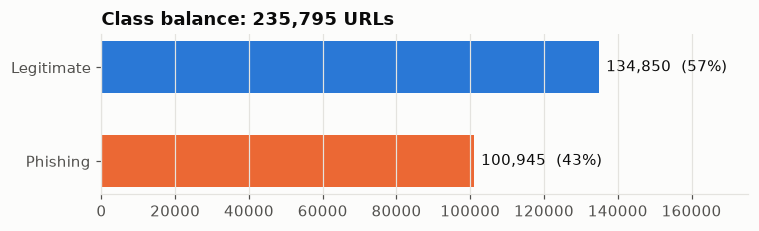

In [4]:
counts = df["is_phishing"].map({0: "Legitimate", 1: "Phishing"}).value_counts()

fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(counts.index, counts.values, color=[LEGIT, PHISH], height=0.55)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_width() + 2000, bar.get_y() + bar.get_height() / 2,
            f"{n:,}  ({n / len(df):.0%})", va="center", color=INK)
ax.set_title("Class balance: 235,795 URLs")
ax.set_xlim(0, counts.max() * 1.3)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

A few random examples of each class. Phishing hosts are **defanged** (`.` becomes `[.]`) so they can't be clicked.

In [5]:
sample = df.groupby("is_phishing").sample(5, random_state=7).copy()
sample["url"] = [u if y == 0 else defang(u) for u, y in zip(sample["url"], sample["is_phishing"])]
sample

,url,is_phishing
117420,https://www.teufelsmoor.eu,0
7364,https://www.ak-berlin.de,0
71301,https://www.missourinet.com,0
120252,https://www.kosmetikahrou.cz,0
56435,https://www.calgarylibrary.ca,0
206363,https://ipfs[.]io/ipfs/bafybeiboyaek3ag2kvurcl4gy4cntezlavvnoe6rkrg7oj72jtyn...,1
187584,https://cf-ipfs[.]com/ipfs/qmrzhm4zqeznvohafhazcid56gxvdi2ztmzvcajy96b6en/ko...,1
193854,https://generatokenapposms--actualiza[.]repl[.]co/,1
203354,https://www[.]valmaxtrading[.]com/wp-admin,1
222294,http://www[.]upcomingsong[.]com,1


## 3. EDA: the shortcut that would have fooled us

Before building features we check whether some simple pattern in the URL *already* gives away the label.
If it does, a model will learn that pattern instead of anything about phishing. This is called **shortcut learning**,
or **label leakage**.

For each pattern below we compute: of all URLs with this pattern, what share is phishing?

In [6]:
after_host = df["url"].str.replace(r"^https?://[^/]+", "", regex=True)
patterns = {
    "Has a path or query after the domain": after_host.str.len().gt(1),
    "Ends with '/'": df["url"].str.endswith("/"),
    "Starts with http:// (not https)": df["url"].str.startswith("http://"),
    "Starts with https://www.": df["url"].str.startswith("https://www."),
}
leak = pd.DataFrame({
    "URLs with pattern": {k: int(m.sum()) for k, m in patterns.items()},
    "share phishing": {k: df.loc[m, "is_phishing"].mean() for k, m in patterns.items()},
})
leak.style.format({"URLs with pattern": "{:,}", "share phishing": "{:.1%}"})

,URLs with pattern,share phishing
Has a path or query after the domain,"28,684",100.0%
Ends with '/',"36,813",100.0%
Starts with http:// (not https),"51,749",100.0%
Starts with https://www.,"137,299",1.8%


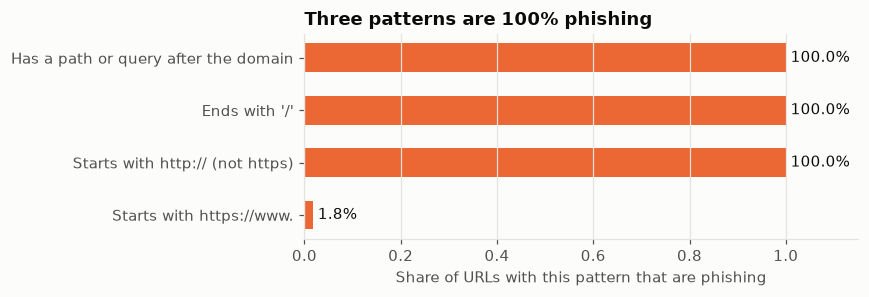

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.8))
share = leak["share phishing"]
bars = ax.barh(share.index, share.values, color=PHISH, height=0.55)
for bar, v in zip(bars, share.values):
    ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.1%}", va="center", color=INK)
ax.set_xlim(0, 1.15)
ax.set_xlabel("Share of URLs with this pattern that are phishing")
ax.set_title("Three patterns are 100% phishing")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**What to take away.**
* **Every** URL with a path, a trailing slash, or `http://` is phishing.
* Legitimate rows are almost all bare homepages like `https://www.something.com`.

This is a quirk of **how the dataset was collected**, not a fact about phishing. Real legitimate links have paths all
the time (`https://github.com/anthropics`). A model trained on full URLs would learn "has a path = phishing", score
99%+ in testing, and then fail on real links.

**Our decision:** the model only sees the **hostname** (lower-cased, `www.` removed). Things in the rest of the link that
genuinely matter (an `@`, a raw IP, `http`) are handled by **rule-based tips** in the app instead.
This one decision is the reason our scores are around 0.78 and not a suspicious 0.99.

## 4. Cleaning: from URLs to unique hosts

`normalize_host()` (in `features.py`) turns any URL into its bare hostname:

In [8]:
for u in ["HTTPS://WWW.PayPal.com/login?x=1", "github.com/anthropics", "http://192.168.0.1:8080/a"]:
    print(f"{u:40} ->  {normalize_host(u)}")

HTTPS://WWW.PayPal.com/login?x=1         ->  paypal.com
github.com/anthropics                    ->  github.com
http://192.168.0.1:8080/a                ->  192.168.0.1


Many URLs share the same host. If the same host appeared in both the training and the test set, the model could simply
**memorise** it and the test score would be inflated. So we keep **one row per host**.
We also drop hosts that appear with *both* labels, because we can't know which label is right.

In [9]:
df["host"] = df["url"].map(normalize_host)
per_host = df.groupby("host")["is_phishing"].agg(["nunique", "first"])
conflicting = int((per_host["nunique"] > 1).sum())
hosts = per_host[per_host["nunique"] == 1]["first"].rename("is_phishing").reset_index()

print(f"URLs:               {len(df):,}")
print(f"Unique hosts:       {len(per_host):,}")
print(f"Conflicting hosts:  {conflicting:,}  (dropped)")
print(f"Final dataset:      {len(hosts):,} hosts, {hosts['is_phishing'].mean():.1%} phishing")

URLs:               235,795
Unique hosts:       219,094
Conflicting hosts:  58  (dropped)
Final dataset:      219,036 hosts, 38.5% phishing


## 5. Feature engineering

Machine-learning models can't read text; they need numbers. `host_features()` turns one hostname into
**16 numbers**, each based on a known phishing trick:

| Feature | What it measures | Phishing trick it catches |
|---|---|---|
| `host_length` | characters in the host | long hosts that pack in brand names |
| `num_subdomains` | labels beyond domain + TLD | `paypal.com.evil.ru` puts the brand *in front* of the real domain |
| `num_hyphens` | `-` count | look-alikes such as `pay-pal-secure` |
| `num_digits`, `digit_ratio` | digits, and digits ÷ length | random IDs, `amaz0n` |
| `is_ip` | host is a raw IP | real companies don't use bare IPs |
| `host_entropy` | Shannon entropy (bits per character) | machine-generated random names |
| `suspicious_keyword_count` | bait words (`login`, `verify`, `secure`, …) | "official-sounding" domains |
| `tld_length`, `is_risky_tld` | the ending, e.g. `.com`, `.xyz` | cheap TLDs abused for phishing |
| `has_punycode` | `xn--` present | homograph attacks (Cyrillic `а` in `аpple`) |
| `longest_label_length` | longest part between dots | junk labels that hide a brand |
| `is_free_hosting` | on firebaseapp, weebly, godaddysites, … | free subdomains cost attackers nothing |
| `vowel_ratio`, `max_consonant_run` | vowel share, longest consonant streak | random strings such as `xkqzvbt` |
| `digit_letter_switches` | letter↔digit changes | ids like `caseid1008934` |

Here are the features for three example links:

In [10]:
examples = {
    "wikipedia.org": "https://www.wikipedia.org",
    "fake PayPal": "http://paypal.com.account-verify.security-check.ru/login",
    "free-hosting id": "https://caseid1008934573489.firebaseapp.com/",
}
pd.DataFrame({name: extract_features(u) for name, u in examples.items()})

,wikipedia.org,fake PayPal,free-hosting id
host_length,13.0000,43.0000,35.0000
num_subdomains,0.0000,3.0000,1.0000
num_hyphens,0.0000,2.0000,0.0000
num_digits,0.0000,0.0000,13.0000
digit_ratio,0.0000,0.0000,0.3714
is_ip,0.0000,0.0000,0.0000
host_entropy,3.3347,4.0941,4.2861
suspicious_keyword_count,0.0000,3.0000,0.0000
tld_length,3.0000,2.0000,3.0000
has_punycode,0.0000,0.0000,0.0000


**Reading the table:** the fake PayPal link has 3 subdomains, 3 bait words (`paypal`, `account`, `verify`) and a risky
TLD (`.ru`). The free-hosting link has 13 digits (a digit ratio of 0.37) and `is_free_hosting = 1`. Wikipedia scores
zero on every risk flag.

Now we compute all 16 features for every host:

In [11]:
t0 = time.perf_counter()
X = pd.DataFrame([host_features(h) for h in hosts["host"]], columns=FEATURE_NAMES)
y = hosts["is_phishing"].to_numpy()
print(f"Feature matrix {X.shape} built in {time.perf_counter() - t0:.1f}s")
X.describe().T[["mean", "std", "min", "max"]].round(3)

Feature matrix (219036, 16) built in 5.6s


,mean,std,min,max
host_length,18.299,9.530,4.000,110.000
num_subdomains,0.388,0.654,0.000,10.000
num_hyphens,0.269,0.734,0.000,26.000
num_digits,0.821,2.692,0.000,67.000
digit_ratio,0.030,0.089,0.000,0.886
is_ip,0.001,0.027,0.000,1.000
host_entropy,3.420,0.411,0.722,4.978
suspicious_keyword_count,0.018,0.140,0.000,4.000
tld_length,2.764,0.586,0.000,13.000
has_punycode,0.001,0.024,0.000,1.000


**Do the features actually separate the classes?** Below, each panel compares the distribution of one feature for
legitimate (blue) and phishing (orange) hosts. Each curve is a share of its own class, so the two classes are comparable
even though their sizes differ. The more the curves differ, the more useful the feature.

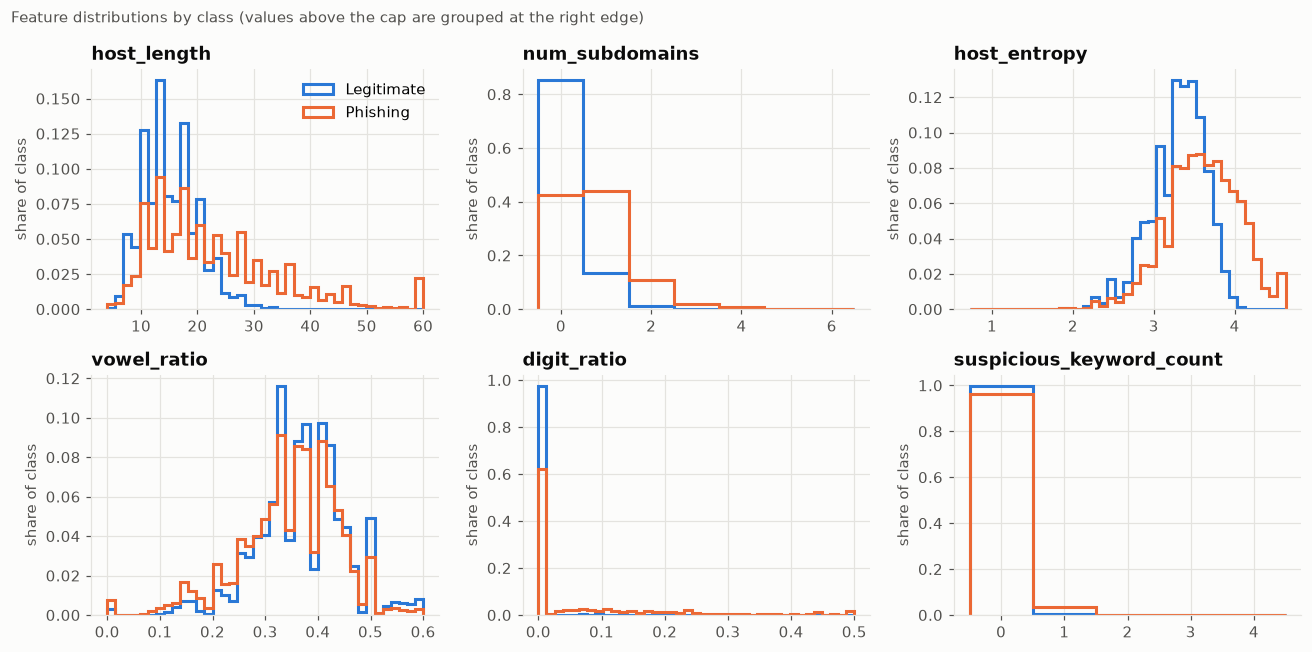

In [12]:
show = ["host_length", "num_subdomains", "host_entropy", "vowel_ratio", "digit_ratio", "suspicious_keyword_count"]
clip = {"host_length": 60, "num_subdomains": 6, "digit_ratio": 0.5, "suspicious_keyword_count": 4}

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, show):
    hi = clip.get(col, X[col].quantile(0.995))
    discrete = col in ("num_subdomains", "suspicious_keyword_count")
    bins = np.arange(-0.5, hi + 1.5) if discrete else np.linspace(X[col].min(), hi, 40)
    for label, colour, name in [(0, LEGIT, "Legitimate"), (1, PHISH, "Phishing")]:
        vals = X.loc[y == label, col].clip(upper=hi)
        ax.hist(vals, bins=bins, histtype="step", linewidth=2, color=colour,
                weights=np.full(len(vals), 1 / len(vals)), label=name)
    ax.set_title(col)
    ax.set_ylabel("share of class")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Feature distributions by class (values above the cap are grouped at the right edge)",
             x=0.01, ha="left", color=MUTED, fontsize=10)
plt.tight_layout()
plt.show()

**What to take away.**
* Phishing hosts are **longer** and have **more subdomains**. Most legitimate hosts have none once `www.` is removed.
* Phishing hosts have **higher entropy** (more random) and more **digits**. Bait words appear in only a few percent of
  phishing hosts, but almost never in legitimate ones.
* The curves **overlap a lot**. No single feature decides the answer, which is why we need a model that combines them,
  and why we should not expect a perfect score.

## 6. Training and comparing three algorithms

**Train/test split.** We hold back 20% of hosts that the model never sees during training, and score it on those.
`stratify=y` keeps the same phishing ratio in both parts, and `random_state=42` makes the split identical on every run,
so results are reproducible.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X.to_numpy(), y, test_size=0.2, stratify=y, random_state=42)
print(f"train: {len(X_train):,} hosts ({y_train.mean():.1%} phishing)")
print(f"test:  {len(X_test):,} hosts ({y_test.mean():.1%} phishing)")

train: 175,228 hosts (38.5% phishing)
test:  43,808 hosts (38.5% phishing)


**The three algorithms**, from simplest to most powerful:

1. **Logistic Regression.** Draws one straight boundary through feature space. Fast and easy to explain, but it can't
   capture rules like "risk only rises past a certain length". It needs `StandardScaler` because the features have very
   different ranges (0–1 vs 0–100).
2. **Random Forest.** Many decision trees, each trained on a random sample; they vote. Handles non-linear patterns.
3. **Histogram Gradient Boosting (HGB).** Builds trees *one after another*, each fixing the previous ones' mistakes.
   Usually the strongest choice for tabular data.

All three use `class_weight="balanced"`, so mistakes on the smaller phishing class count more.
These are the same settings as the best runs logged in MLflow by `train.py`.

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=600, class_weight="balanced", random_state=42),
}

rows, probas = {}, {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - t0
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    rows[name] = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
                  "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, p), "train seconds": seconds}
    print(f"{name:20} trained in {seconds:5.1f}s")

results = pd.DataFrame(rows).T
results.style.format("{:.3f}").format({"train seconds": "{:.1f}"}).highlight_max(
    subset=["accuracy", "precision", "recall", "F1", "ROC-AUC"], color="#cde2fb")

Logistic Regression  trained in   0.4s


Random Forest        trained in  12.3s


Gradient Boosting    trained in   6.2s


,accuracy,precision,recall,F1,ROC-AUC,train seconds
Logistic Regression,0.841559,0.880784,0.680100,0.767541,0.845486,0.4
Random Forest,0.852470,0.904125,0.689536,0.782383,0.862698,12.3
Gradient Boosting,0.851968,0.891804,0.700042,0.784372,0.867137,6.2


**What the metrics mean here** (phishing = positive class):

| Metric | Plain-English meaning |
|---|---|
| **Precision** | Of the links we flagged, how many really were phishing? Low precision = lots of false alarms. |
| **Recall** | Of all the phishing links, how many did we catch? Low recall = phishing slips through. |
| **F1** | One number that balances precision and recall (their harmonic mean). Our selection metric. |
| **ROC-AUC** | How well the model *ranks* phishing above legitimate across every possible threshold. 0.5 = coin flip, 1.0 = perfect. |

**What to take away.** Gradient Boosting has the best F1 and ROC-AUC, so it is the deployed model. Random Forest is
close but about twice as slow to train. Logistic Regression is behind on every metric, which tells us the patterns are
**non-linear**.
All three have high precision (~0.88–0.90) but lower recall (~0.68–0.70). The model rarely raises false alarms, but it
misses about 3 in 10 phishing hosts. Section 10 shows why.

## 7. Evaluating the best model

**ROC curves** show the trade-off between catching phishing (true-positive rate) and raising false alarms
(false-positive rate) at every threshold. A curve closer to the top-left corner is better, and the area under it is the
ROC-AUC.

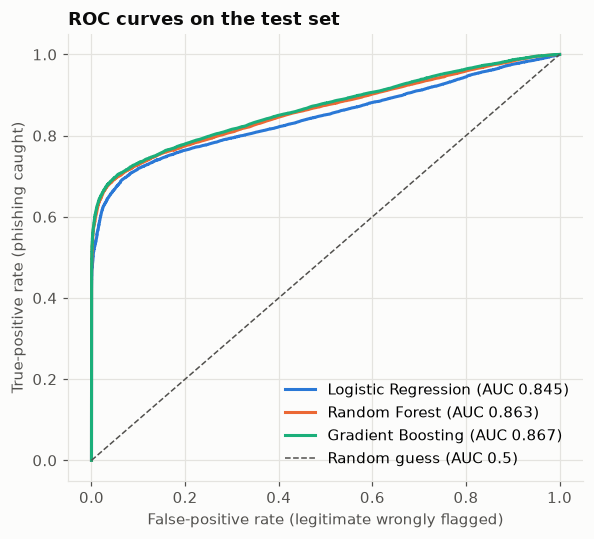

In [15]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5.5, 5))
for (name, p), colour in zip(probas.items(), [LEGIT, PHISH, THIRD]):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=colour, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--", label="Random guess (AUC 0.5)")
ax.set_xlabel("False-positive rate (legitimate wrongly flagged)")
ax.set_ylabel("True-positive rate (phishing caught)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Confusion matrix** for Gradient Boosting at the default threshold (0.5): each test host lands in one of four boxes.

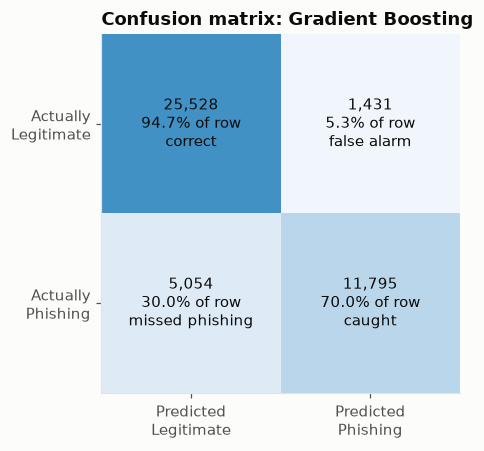

In [16]:
from sklearn.metrics import confusion_matrix

best_name = results["F1"].idxmax()
best = models[best_name]
p_best = probas[best_name]
cm = confusion_matrix(y_test, (p_best >= 0.5).astype(int))

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.6)
names = ["Legitimate", "Phishing"]
notes = [["correct", "false alarm"], ["missed phishing", "caught"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{cm[i, j] / cm[i].sum():.1%} of row\n{notes[i][j]}",
                ha="center", va="center", color=INK, fontsize=10)
ax.set_xticks([0, 1], [f"Predicted\n{n}" for n in names])
ax.set_yticks([0, 1], [f"Actually\n{n}" for n in names])
ax.grid(False)
ax.set_title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.show()

**What to take away.** About 95% of legitimate hosts are correctly passed and only ~5% are false alarms. On the phishing
side about 70% are caught and 30% are missed. For a link checker, a low false-alarm rate matters: if it cried wolf on
every link, people would stop trusting it.

## 8. Explainability: which features matter?

Gradient Boosting doesn't come with simple feature weights, so we use **permutation importance**. We shuffle one feature
at a time and measure how much the F1 score drops. If shuffling a feature hurts a lot, the model relies on it.
If it changes nothing, the feature isn't pulling its weight.

(We use a 20,000-host sample of the test set to keep this fast.)

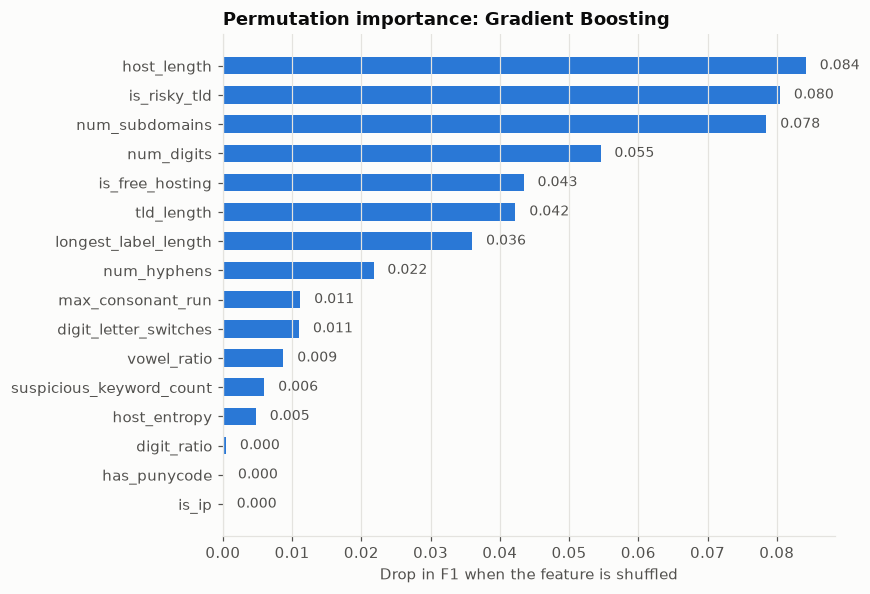

In [17]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(0)
idx = rng.choice(len(X_test), 20_000, replace=False)
imp = permutation_importance(best, X_test[idx], y_test[idx], scoring="f1",
                             n_repeats=5, random_state=0, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURE_NAMES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, importance.values, color=LEGIT, height=0.6)
for i, v in enumerate(importance.values):
    ax.text(max(v, 0) + 0.002, i, f"{v:.3f}", va="center", color=MUTED, fontsize=9)
ax.set_xlabel("Drop in F1 when the feature is shuffled")
ax.set_title(f"Permutation importance: {best_name}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**What to take away.**
* The model leans most on **length**, the **TLD** (`is_risky_tld`, `tld_length`) and **subdomains**, followed by digits
  and free hosting. That matches the distribution charts in section 5.
* `digit_ratio` scores 0 even though digits matter. It is just `num_digits ÷ host_length`, and both of those are already
  features, so shuffling it loses no information. Permutation importance gives **low scores to redundant features**;
  low here does not mean "useless on its own". The same partly explains the small scores for `host_entropy` and
  `vowel_ratio`, which overlap with length and digits.
* `is_ip` and `has_punycode` are very rare (about 0.1% of hosts each), so they barely move the overall F1. They still
  matter for the individual links where they fire, which is why the app also shows them as **tips**.

## 9. Choosing the threshold

The model outputs a **probability**, and we flag a link as phishing when it is ≥ 0.5. That 0.5 is a choice, not a law.
Lowering it catches more phishing (recall ↑) but raises more false alarms (precision ↓).

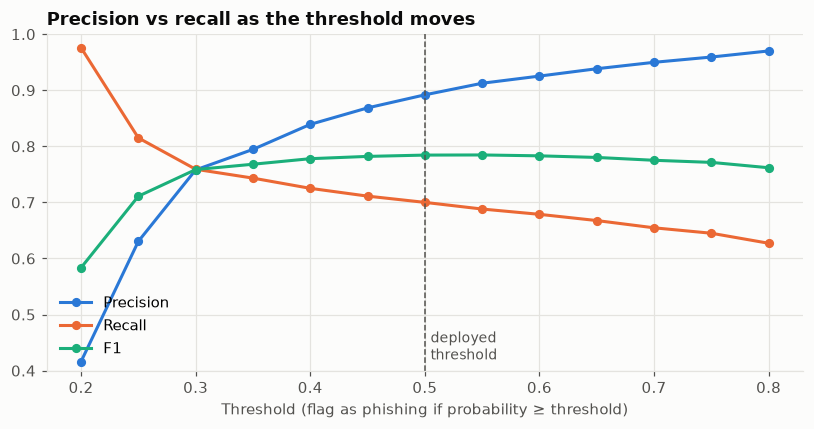

threshold,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80
precision,0.416,0.631,0.758,0.795,0.839,0.869,0.892,0.912,0.925,0.938,0.950,0.959,0.970
recall,0.976,0.815,0.759,0.743,0.725,0.711,0.700,0.688,0.679,0.668,0.655,0.645,0.627
F1,0.584,0.711,0.759,0.768,0.778,0.782,0.784,0.785,0.783,0.780,0.775,0.771,0.762


In [18]:
thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)
trade = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(y_test, p_best >= t) for t in thresholds],
    "recall": [recall_score(y_test, p_best >= t) for t in thresholds],
    "F1": [f1_score(y_test, p_best >= t) for t in thresholds],
})

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(trade["threshold"], trade["precision"], color=LEGIT, marker="o", markersize=5, label="Precision")
ax.plot(trade["threshold"], trade["recall"], color=PHISH, marker="o", markersize=5, label="Recall")
ax.plot(trade["threshold"], trade["F1"], color=THIRD, marker="o", markersize=5, label="F1")
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--")
ax.text(0.505, 0.42, "deployed\nthreshold", color=MUTED, fontsize=9)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("Threshold (flag as phishing if probability ≥ threshold)")
ax.set_title("Precision vs recall as the threshold moves")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
trade.set_index("threshold").round(3).T

**What to take away.**
* **F1 is almost flat between 0.40 and 0.60** (0.778–0.785), so 0.5 already sits at the F1 peak.
* Moving the threshold is a trade, not a free gain. Dropping it to 0.35 catches about 4 more phishing hosts in 100
  (recall 0.70 → 0.74) but costs about 10 points of precision (0.89 → 0.80). Below 0.30 precision collapses.
* A bank's email filter might accept more false alarms to catch more phishing; a public link checker that must not annoy
  users should keep 0.5. We keep 0.5 and list tuning on a separate validation set as future work. (Choosing it on the
  *test* set, as here, would make the test score look better than it really is.)

## 10. Error analysis: what does the model get wrong?

Looking at actual mistakes tells us more than any metric. Phishing hosts are defanged.

In [19]:
test_hosts = hosts["host"].to_numpy()[
    train_test_split(np.arange(len(hosts)), test_size=0.2, stratify=y, random_state=42)[1]]
errors = pd.DataFrame({"host": test_hosts, "actual": y_test, "p_phishing": p_best.round(3)})

missed = errors[(errors.actual == 1) & (errors.p_phishing < 0.5)].sort_values("p_phishing").head(8)
false_alarm = errors[(errors.actual == 0) & (errors.p_phishing >= 0.5)].sort_values(
    "p_phishing", ascending=False).head(8)
missed = missed.assign(host=missed["host"].map(defang))

print("Missed phishing (the model was confident they were safe):")
display(missed)
print("False alarms (legitimate hosts the model flagged):")
display(false_alarm)

Missed phishing (the model was confident they were safe):


,host,actual,p_phishing
474,umf[.]uem[.]mz,1,0.032
29863,uok[.]org,1,0.041
637,ngx[.]net,1,0.046
1544,iul[.]edu[.]mx,1,0.050
31128,icri[.]iria[.]org[.]in,1,0.067
30317,gg[.]net[.]co,1,0.069
17756,iew[.]net,1,0.069
9813,ueea[.]edu[.]ec,1,0.070


False alarms (legitimate hosts the model flagged):


,host,actual,p_phishing
1454,family-tree.cobboldfht.com,0,0.996
35368,iswc2017.semanticweb.org,0,0.994
1703,iso25000.com,0,0.991
4123,httpvshttps.com,0,0.989
9378,79798282.net,0,0.986
22742,san-francisco.investinluxembourg.us,0,0.984
5944,chelmsford.anglican.org,0,0.983
32266,weirdscifi.ratiosemper.com,0,0.983


**What to take away.**
* **Missed phishing** hosts are short, ordinary-looking names, many on academic or country domains (`.edu.mx`, `.org`,
  `.org.in`). These are very likely **legitimate sites that were hacked** and used to host a phishing page. The hostname
  really is innocent; the phishing is in the path, which the model deliberately ignores. Catching these needs page-content
  or reputation features, not a better hostname model.
* **False alarms** tend to be real sites with long, hyphenated or unusual names, or uncommon TLDs, which are exactly the
  traits phishing hosts share.

This is the honest ceiling of a hostname-only model, and it is why the report lists page-content and domain-age features
as next steps.

## 11. The saved model and the API

`train.py` logged every experiment to **MLflow** (`mlflow.db`) and saved the best run to `model/model.joblib`.
Here is that run's summary, which the API also reports at `/health`:

In [20]:
import json
meta = json.loads((ROOT / "model" / "model_meta.json").read_text())
{k: meta[k] for k in ["algorithm", "params", "accuracy", "precision", "recall", "f1", "roc_auc"]}

{'algorithm': 'hgb',
 'params': {'learning_rate': 0.05, 'max_iter': 600},
 'accuracy': 0.852,
 'precision': 0.8918,
 'recall': 0.7,
 'f1': 0.7844,
 'roc_auc': 0.8671}

**The data contract.** The API never passes raw input straight to the model. Every request is checked by the Pydantic
schema `PhishFeatures` in `app.py`: correct types, allowed ranges, no unknown fields, no NaN, and values that are
consistent with each other. Anything else is rejected **before** it reaches the model; over HTTP that's a **422** error.

In [21]:
import os, tempfile
os.environ["LOG_PATH"] = str(Path(tempfile.gettempdir()) / "notebook_predictions.jsonl")  # keep the real log clean

from pydantic import ValidationError
from app import PhishFeatures

good = extract_features("https://www.wikipedia.org")
bad_inputs = {
    "digit_ratio = 1.5 (max is 1.0)": {**good, "digit_ratio": 1.5},
    "host_length = '12' (string, not int)": {**good, "host_length": "12"},
    "vowel_ratio = NaN": {**good, "vowel_ratio": float("nan")},
    "10 digits in a 5-char host": {**good, "host_length": 5, "num_digits": 10, "longest_label_length": 5},
    "unknown field 'colour'": {**good, "colour": 1},
}
print("valid input accepted:", PhishFeatures(**good).host_length == good["host_length"])
for label, payload in bad_inputs.items():
    try:
        PhishFeatures(**payload)
        print(f"ACCEPTED (unexpected!)  {label}")
    except ValidationError as e:
        print(f"rejected  {label:38} -> {e.errors()[0]['msg']}")

valid input accepted: True
rejected  digit_ratio = 1.5 (max is 1.0)         -> Input should be less than or equal to 1
rejected  host_length = '12' (string, not int)   -> Input should be a valid integer
rejected  vowel_ratio = NaN                      -> Input should be a finite number
rejected  10 digits in a 5-char host             -> Value error, num_digits, num_hyphens and longest_label_length must be <= host_length
rejected  unknown field 'colour'                 -> Extra inputs are not permitted


**End to end.** Finally, the full request path the live app uses: URL in → hostname → 16 features → contract check →
model → probability plus 2–3 rule-based tips. `TestClient` calls the real FastAPI app in-process, with no server needed.

In [22]:
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)
for url in ["https://github.com/anthropics",
            "http://paypal.com.account-verify.security-check.ru/login",
            "http://192.168.10.5/login"]:
    r = client.post("/predict-url", json={"url": url}).json()
    shown = url if r["verdict"] == "legitimate" else defang(url)
    print(f"{shown}\n  -> {r['verdict'].upper()}  (p = {r['phishing_probability']})")
    for tip in r["tips"]:
        print("     •", tip)
    print()

print("Invalid URL 'notaurl' ->", client.post("/predict-url", json={"url": "notaurl"}).status_code)

https://github.com/anthropics
  -> LEGITIMATE  (p = 0.2416)
     • Looks normal, but still check the spelling of the domain before signing in.
     • If a message pressures you to act urgently, verify through the official app or helpline.

http://paypal[.]com[.]account-verify[.]security-check[.]ru/login
  -> PHISHING  (p = 0.9999)
     • This link uses http, not https, so anything you type is sent unencrypted.
     • The domain itself contains words like 'login', 'verify' or 'secure'. Real sites rarely need them in the domain name.
     • Many subdomains. The part that matters is the end: this site belongs to 'security-check.ru'.

http://192[.]168[.]10[.]5/login
  -> PHISHING  (p = 0.9996)
     • This link uses http, not https, so anything you type is sent unencrypted.
     • The address is a raw IP number instead of a name. Real companies don't send you to bare IP addresses.
     • Don't enter passwords or OTPs here. Open the official site by typing its address yourself.

Invalid URL 

## 12. Conclusions

**What we built.** A phishing-domain classifier trained on 219,036 unique hosts from PhiUSIIL, using 16 features we
engineered ourselves. The best model, Histogram Gradient Boosting, reaches **F1 ≈ 0.78, ROC-AUC ≈ 0.87, precision ≈
0.89, recall ≈ 0.70** on held-out hosts. It is served by a validated FastAPI app, tested by 22 pytest tests,
containerised with Docker, checked by GitHub Actions on every push, and deployed on Render.

**The most important lesson.** The dataset contained a shortcut: every URL with a path was phishing. A model trained on
full URLs would have scored near-perfectly and been useless in practice. Checking for shortcuts *before* modelling, and
restricting the model to the hostname, is what makes our 0.78 an honest number.

**Limitations**
* Hostname only: phishing hosted on a hacked legitimate site is invisible to the model.
* Legitimate training data is mostly homepages, so legitimate login subdomains (e.g. `login.microsoftonline.com`) can be
  flagged.
* Recall is about 0.70: some phishing domains look completely ordinary.
* The data is from 2023, and attack patterns change.

**Next steps**
* Add domain-age (WHOIS) and page-content features.
* Tune the threshold on a separate validation set.
* Evaluate on a newer dataset, and retrain when `drift_check.py` flags drift in live traffic.